# Problem 1 · Interval bound propagation on MNIST


In [1]:
import copy
import json
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
torch.manual_seed(0)
out = Path('results')
out.mkdir(exist_ok=True)
print('Training device:', device, '| PyTorch', torch.__version__)

Training device: cpu | PyTorch 2.14.1


In [2]:
def load_mnist(train):
    cache = Path('../../hw2/q4/mnist_data')
    root = cache if (cache / 'MNIST/raw').is_dir() else Path('data')
    ds = torchvision.datasets.MNIST(root, train=train, download=True)
    return ds.data.float().div(255).unsqueeze(1).to(device), ds.targets.to(device)


def batches(x, y, batch_size):
    for idx in torch.randperm(len(x), device=x.device).split(batch_size):
        yield x[idx], y[idx]


def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)


def linear_layers(model):
    return [layer for layer in model if isinstance(layer, nn.Linear)]


x_train, y_train = load_mnist(True)
x_test, y_test = load_mnist(False)
print(x_train.shape, x_test.shape)

torch.Size([60000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


## Training


In [3]:
def ibp_margin_bounds(model, x, eps, y):
    x = x.flatten(1)
    lo, hi = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    layers = linear_layers(model)
    for layer in layers[:-1]:
        mid = layer((hi + lo) / 2)
        rad = ((hi - lo) / 2) @ layer.weight.abs().T
        lo, hi = (mid - rad).relu(), (mid + rad).relu()
    last = layers[-1]
    w = last.weight[y, None] - last.weight[None]
    b = last.bias[y, None] - last.bias[None]
    mid, rad = ((hi + lo) / 2).unsqueeze(2), ((hi - lo) / 2).unsqueeze(2)
    return (w @ mid - w.abs() @ rad).squeeze(2) + b

In [4]:
def fit(initial, robust, epochs=20, batch_size=512):
    torch.manual_seed(0)
    model = copy.deepcopy(initial).train()
    opt = torch.optim.Adam(model.parameters(), lr=0.004)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    times = []
    n_batches = (len(x_train) + batch_size - 1) // batch_size
    for epoch in range(epochs):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = perf_counter()
        for i, (x, y) in enumerate(batches(x_train, y_train, batch_size)):
            loss = F.cross_entropy(model(x), y)
            ramp = min(1.0, max(0.0, (epoch + i / n_batches - 1) / 10))
            if robust and ramp > 0:
                kappa = 1 - 0.5 * ramp
                margins = ibp_margin_bounds(model, x, 0.1 * ramp, y)
                loss = kappa * loss + (1 - kappa) * F.cross_entropy(-margins, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        times.append(perf_counter() - start)
    return model.eval(), times


initial = make_model()
models, times = {}, {}
for name, robust in [('Standard', False), ('IBP', True)]:
    models[name], times[name] = fit(initial, robust)
    print(f'{name}: {sum(times[name]):.2f} s for 20 epochs')

Standard: 1.47 s for 20 epochs
IBP: 6.03 s for 20 epochs


## Verification and empirical attack


In [5]:
def affine_interval(lo, hi, w, b):
    pos, neg = w.clamp_min(0), w.clamp_max(0)
    return lo @ pos.T + hi @ neg.T + b, hi @ pos.T + lo @ neg.T + b


@torch.no_grad()
def box_certified(model, x, y, eps):
    x = x.double().flatten(1)
    lo, hi = (x - eps).clamp(0, 1), (x + eps).clamp(0, 1)
    layers = linear_layers(model)
    for layer in layers[:-1]:
        lo, hi = affine_interval(lo, hi, layer.weight.double(), layer.bias.double())
        lo, hi = lo.relu(), hi.relu()
    w, b = layers[-1].weight.double(), layers[-1].bias.double()
    w, b = w[y, None] - w[None], b[y, None] - b[None]
    margins = (w.clamp_min(0) * lo[:, None] + w.clamp_max(0) * hi[:, None]).sum(-1) + b
    margins.scatter_(1, y[:, None], float('inf'))
    return margins.amin(1) > 0


def pgd_linf(model, x, y, eps, steps=40, restarts=2):
    low, high = (x - eps).clamp_min(0), (x + eps).clamp_max(1)
    witness = x.clone()
    failed = model(x).detach().argmax(1) != y
    for _ in range(restarts):
        adv = (x + (torch.rand_like(x) * 2 - 1) * eps).clamp(0, 1)
        for i in range(steps + 1):
            adv = adv.detach().requires_grad_(True)
            logits = model(adv)
            wrong = logits.detach().argmax(1) != y
            newly_failed = wrong & ~failed
            witness[newly_failed] = adv.detach()[newly_failed]
            failed |= wrong
            if i < steps:
                grad, = torch.autograd.grad(F.cross_entropy(logits, y), adv)
                adv = (adv.detach() + (2.5 * eps / steps) * grad.sign()).clamp(low, high)
    return ~failed, witness

In [6]:
def evaluate_radius(model, eps, collect=False):
    torch.manual_seed(481 + round(100 * eps))
    counts = dict(clean=0, verified=0, pgd=0)
    examples = []
    for start in range(0, len(y_test), 512):
        x, y = x_test[start:start + 512], y_test[start:start + 512]
        correct = model(x).detach().argmax(1) == y
        certified = box_certified(model, x, y, eps)
        robust, witness = pgd_linf(model, x, y, eps)
        assert (certified <= robust).all() and (robust <= correct).all()
        assert (witness - x).abs().max() <= eps + 1e-6
        assert witness.min() >= 0 and witness.max() <= 1
        if collect and not examples:
            flipped = (correct & ~robust).nonzero().flatten()
            if len(flipped):
                j = flipped[0].item()
                rec = dict(index=start+j, label=int(y[j]), epsilon=eps,
                           prediction=int(model(witness[j:j+1]).detach().argmax(1)),
                           distance=float((witness[j] - x[j]).abs().max()))
                examples.append((rec, x[j, 0].cpu(), witness[j, 0].cpu()))
        for key, mask in zip(counts, (correct, certified, robust)):
            counts[key] += mask.sum().item()
    return dict(epsilon=eps, n=len(y_test), **counts,
                clean_flipped=counts['clean'] - counts['pgd']), examples


baseline, _ = evaluate_radius(models['Standard'], 0.1)
rows, examples = [], []
for step in range(1, 11):
    row, found = evaluate_radius(models['IBP'], step / 100, collect=step in (1, 5, 10))
    rows.append(row)
    examples.extend(found)
    print(f"eps {row['epsilon']:.2f}   verified {row['verified']/100:.2f}%   "
          f"PGD {row['pgd']/100:.2f}%   clean images flipped {row['clean_flipped']}")
assert all(a['verified'] >= b['verified'] for a, b in zip(rows, rows[1:]))
summary = dict(device=str(device), torch=str(torch.__version__), seed=0,
               epoch_seconds=times, standard=baseline, ibp=rows, examples=[e[0] for e in examples])
(out / 'metrics.json').write_text(json.dumps(summary, indent=2) + '\n')
print('Standard (counts):', baseline)

eps 0.01   verified 93.86%   PGD 93.93%   clean images flipped 69
eps 0.02   verified 93.01%   PGD 93.20%   clean images flipped 142
eps 0.03   verified 92.01%   PGD 92.29%   clean images flipped 233
eps 0.04   verified 90.91%   PGD 91.42%   clean images flipped 320
eps 0.05   verified 89.63%   PGD 90.34%   clean images flipped 428
eps 0.06   verified 88.23%   PGD 89.32%   clean images flipped 530
eps 0.07   verified 86.64%   PGD 88.01%   clean images flipped 661
eps 0.08   verified 84.77%   PGD 86.58%   clean images flipped 804
eps 0.09   verified 82.50%   PGD 84.97%   clean images flipped 965
eps 0.10   verified 79.98%   PGD 83.22%   clean images flipped 1140
Standard (counts): {'epsilon': 0.1, 'n': 10000, 'clean': 9714, 'verified': 0, 'pgd': 172, 'clean_flipped': 9542}


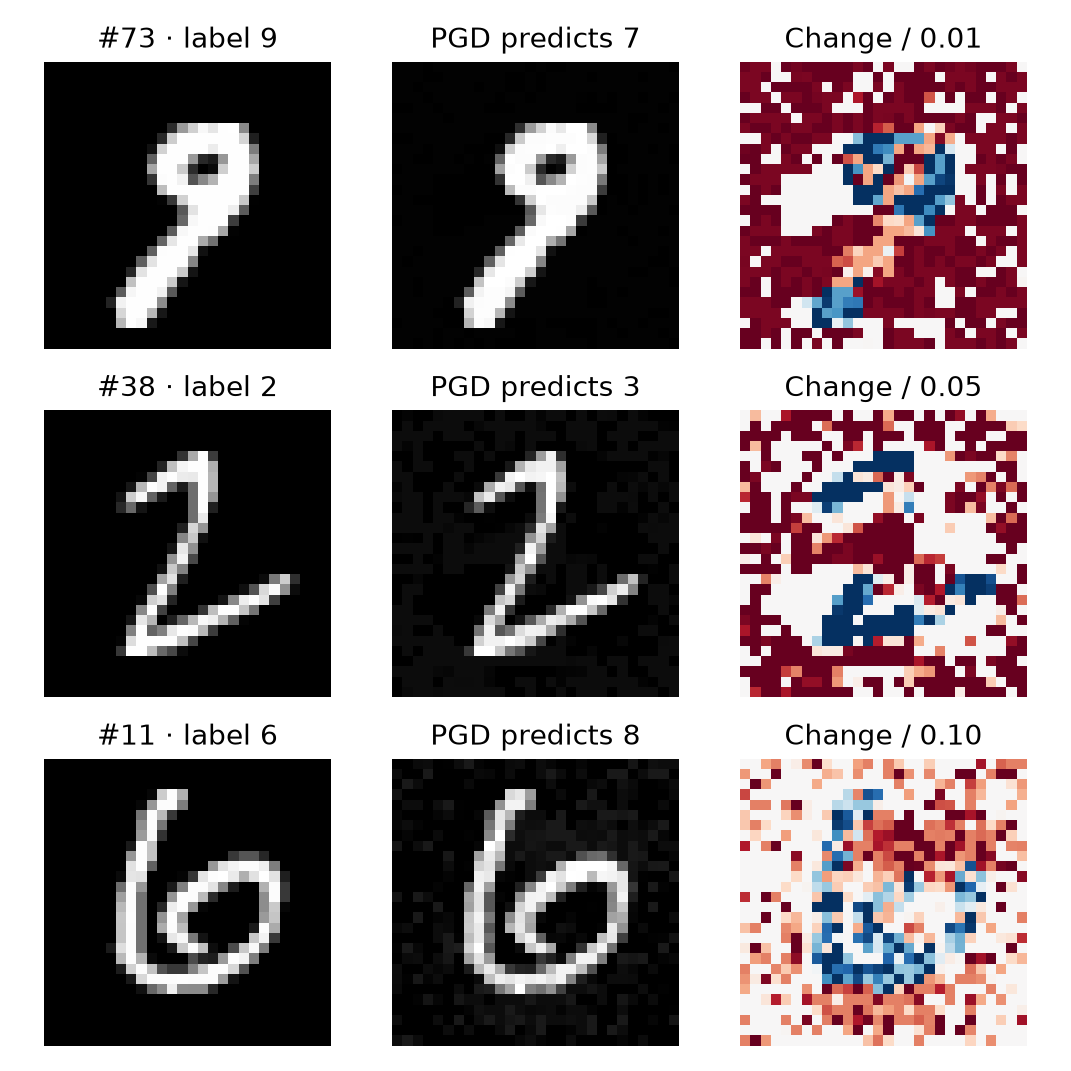

In [7]:
fig, axes = plt.subplots(len(examples), 3, figsize=(6.3, 2.1 * len(examples)), squeeze=False)
for (rec, clean, adv), ax in zip(examples, axes):
    ax[0].imshow(clean, cmap='gray', vmin=0, vmax=1)
    ax[1].imshow(adv, cmap='gray', vmin=0, vmax=1)
    r = rec['epsilon']
    ax[2].imshow((adv - clean) / r, cmap='RdBu_r', vmin=-1, vmax=1)
    ax[0].set_title(f"#{rec['index']} · label {rec['label']}")
    ax[1].set_title(f"PGD predicts {rec['prediction']}")
    ax[2].set_title(f"Change / {r:.2f}")
    for axis in ax:
        axis.axis('off')
fig.tight_layout()
fig.savefig(out / 'counterexamples.png', dpi=170)
plt.show()